<a href="https://colab.research.google.com/github/LinaMariaCastro/curso-ia-para-economia/blob/main/clases/5_Aprendizaje_supervisado/6_Competencia_Seleccion_Mejor_Modelo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Inteligencia Artificial con Aplicaciones en Economía I**

- 👩‍🏫 **Profesora:** [Lina María Castro](https://www.linkedin.com/in/lina-maria-castro)  
- 📧 **Email:** [lmcastroco@gmail.com](mailto:lmcastroco@gmail.com)  
- 🎓 **Universidad:** Universidad Externado de Colombia - Facultad de Economía

# 🏆 **Competencia Selección del Mejor Modelo**

**ESTÁ PROHIBIDO EL USO DE GRANDES MODELOS DE LENGUAJE COMO CLAUDE, CHATGPT, GEMINI, ENTRE OTROS, PARA RESOLVER ESTE EJERCICIO**

**Trabajo en parejas**

**Objetivo:** Predecir las ventas de una compañía (`Sales`) teniendo en cuenta su inversión en publicidad.

**Dataset:** `train_df_ventas.csv` disponible en el repositorio del curso o en la carpeta compartida en Driva.

**IMPORTANTE:** Los estudiantes solo tendrán acceso al conjunto de entrenamiento: `train`. La docente es la única persona que tiene acceso a `test`.

**Metodología:**
1.  Cargar y explorar los datos.
2.  Preprocesar los datos si es necesario.
3.  De los siguientes modelos, entrenar por lo menos 2:
    - Regresión Lineal
    - Regresión Polinómica
    - KNN Regressor
    - Decision Tree Regressor
    - Random Forest Regressor
    - Gradient Boosting Regressor
    - XGBoost Regressor
4.  Si lo considera necesario, usar `GridSearchCV` con Validación Cruzada (`cv=5`) para optimizar los hiperparámetros. La métrica de optimización debe ser el **RMSE** (Root Mean Squared Error), por lo que debe usar `scoring='neg_root_mean_squared_error'` (el valor será negativo y se multiplicará por -1 al final).
5.  Comparar los modelos y seleccionar el mejor, teniendo en cuenta el menor RMSE.

**Forma de entrega:**

- Nombrar el archivo de la siguiente forma: “Competencia_apellidos.ipynb”.
- Suba el Jupyter Notebook a su cuenta en Github y envíe el link en el siguiente Forms: https://forms.cloud.microsoft/r/Hv1FLMX8Tc. No olvide indicar claramente cuál es el modelo seleccionado.

**IMPORTANTE:** No se recibirán respuestas en Google Colab, el notebook debe estar subido en Github.

**Plazo de entrega:**

6 de noviembre de 2026, máximo a las 11:59 p.m. Tenga en cuenta que luego de esa hora el formulario en forms se cierra. El Jupupyter Notebook también debe quedar subido en Github antes de esa hora.

**Calificación**

La docente, evaluará el modelo seleccionado por ustedes en el `test set`.

El proceso seguirá estas reglas:

- **Criterio de Ganador:** El equipo que tenga todo el procedimiento correcto y obtenga el Root Mean Squared Error (RMSE) más bajo en el test set ganará la competencia.

- **Criterio de Desempate:** En caso de empate en el RMSE, se otorgará la ventaja al equipo que haya entrenado y evaluado más modelos.

- **Validación de Procedimiento:** Es obligatorio que el código sea reproducible por la docente (no olivde colocar las semillas en los procesos aleatorios). Si el script contiene errores, el equipo quedará fuera de la competencia.

- **Está prohibido el uso de IA generativa:** Si se evidencia el uso de IA generativa en el desarrollo de este ejercicio, el equipo quedará fuera de la competencia.

- **Es imposible que dos equipos hayan entrenados los mismos modelos:** El abanico de posibles hiperparámetros y de modelos es muy amplio, por lo que si el trabajo de dos equipos es igual o muy parecido, ambos equipos quedarán fuera de la competencia.

**Premio**: Se subirá a 5.0 aquella nota que tengan más baja entre quices, talleres y parcial.

**Explicación de las variables:**

- Sales: Ventas (millones USD). --> **Esta es la variable objetivo**
- TV: Gasto en promoción televisiva (millones USD).
- Radio: Gasto en promoción radiofónica (millones USD).
- Social Media: Gasto en promoción en redes sociales (millones USD).
- Influencer: Indica si la promoción se realizó en colaboración con Mega, Macro, Nano o Micro influencers.


**Nombres estudiantes del equipo:**

- Daniel Felipe Peña Palacios
- Santiago Gonzalez Espejo

# **Desarrollo**

***1_Datos***

In [ ]:

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

pd.options.display.max_columns = None
pd.options.display.float_format = '{:,.2f}'.format
sns.set(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

df = pd.read_csv('train_df_ventas.csv')

print("--- Primeras filas ---")
display(df.head())

print("\n--- Información del dataset ---")
df.info()

print("\n--- Estadísticas descriptivas ---")
display(df.describe())

--- Primeras filas ---


,TV,Social Media,Influencer,Radio,Sales
0,25.41,3.22,Micro,22.24,262.40
1,16.84,1.58,Micro,22.24,207.19
2,24.08,6.71,Micro,22.60,233.74
3,11.50,2.52,Nano,21.42,162.32
4,8.18,0.15,Nano,22.20,114.20



--- Información del dataset ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3409 entries, 0 to 3408
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   TV            3409 non-null   float64
 1   Social Media  3409 non-null   float64
 2   Influencer    3409 non-null   object 
 3   Radio         3409 non-null   float64
 4   Sales         3409 non-null   float64
dtypes: float64(4), object(1)
memory usage: 133.3+ KB

--- Estadísticas descriptivas ---


,TV,Social Media,Radio,Sales
count,"3,409.00","3,409.00","3,409.00","3,409.00"
mean,18.10,3.34,22.09,191.55
std,9.67,2.20,0.47,93.50
min,0.00,0.00,21.03,31.20
25%,10.40,1.57,21.72,110.44
50%,17.79,3.06,22.06,188.67
75%,25.65,4.81,22.45,271.54
max,48.87,13.98,23.21,362.04


***2_Variables***

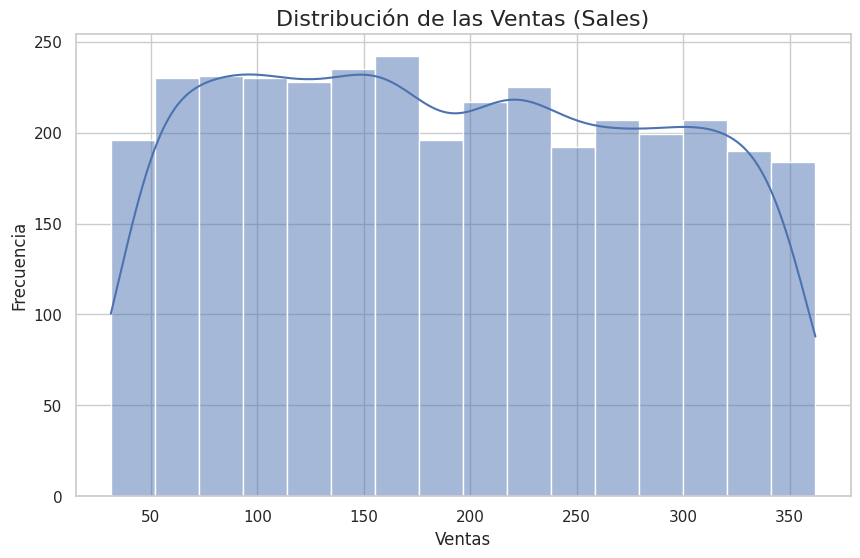

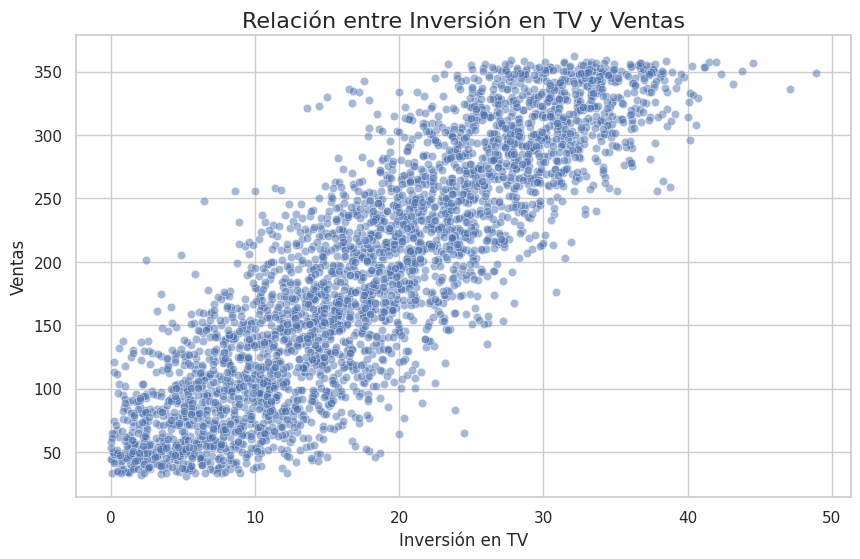


--- Dataset procesado y listo para modelar ---


,TV,Social Media,Radio,Sales,Influencer_Mega,Influencer_Micro,Influencer_Nano
0,25.41,3.22,22.24,262.40,0,1,0
1,16.84,1.58,22.24,207.19,0,1,0
2,24.08,6.71,22.60,233.74,0,1,0
3,11.50,2.52,21.42,162.32,0,0,1
4,8.18,0.15,22.20,114.20,0,0,1


In [ ]:

plt.figure(figsize=(10, 6))
sns.histplot(df['Sales'], kde=True)
plt.title('Distribución de las Ventas (Sales)', fontsize=16)
plt.xlabel('Ventas')
plt.ylabel('Frecuencia')
plt.show()

plt.figure(figsize=(10, 6))
sns.scatterplot(x='TV', y='Sales', data=df, alpha=0.5)
plt.title('Relación entre Inversión en TV y Ventas', fontsize=16)
plt.xlabel('Inversión en TV')
plt.ylabel('Ventas')
plt.show()


df_procesado = pd.get_dummies(df, columns=['Influencer'], drop_first=True, dtype=int)

print("\n--- Dataset procesado y listo para modelar ---")
display(df_procesado.head())

***3_Regresión***

In [ ]:

X = df_procesado.drop('Sales', axis=1)


y = df_procesado['Sales']


X_con_constante = sm.add_constant(X)


modelo_econometrico = sm.OLS(y, X_con_constante).fit()


print(modelo_econometrico.summary())

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.774
Model:                            OLS   Adj. R-squared:                  0.773
Method:                 Least Squares   F-statistic:                     1938.
Date:                Fri, 06 Nov 2026   Prob (F-statistic):               0.00
Time:                        22:33:41   Log-Likelihood:                -17774.
No. Observations:                3409   AIC:                         3.556e+04
Df Residuals:                    3402   BIC:                         3.561e+04
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const             -564.8141     39.180  

***4***

In [ ]:

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Tamaño del dataset original: {X.shape[0]} filas")
print(f"Tamaño del set de entrenamiento: {X_train.shape[0]} filas")
print(f"Tamaño del set de prueba: {X_test.shape[0]} filas\n")


modelo_ml = LinearRegression()
modelo_ml.fit(X_train, y_train)


predicciones = modelo_ml.predict(X_test)

mse = mean_squared_error(y_test, predicciones)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, predicciones)

print(f"Métricas de Desempeño sobre el Conjunto de Prueba:")
print(f"-------------------------------------------------")
print(f"Error Cuadrático Medio (MSE): {mse:.4f}")
print(f"Raíz del Error Cuadrático Medio (RMSE): {rmse:.4f}")
print(f"Coeficiente de Determinación (R-cuadrado): {r2:.4f}")

Tamaño del dataset original: 3409 filas
Tamaño del set de entrenamiento: 2727 filas
Tamaño del set de prueba: 682 filas

Métricas de Desempeño sobre el Conjunto de Prueba:
-------------------------------------------------
Error Cuadrático Medio (MSE): 2003.6408
Raíz del Error Cuadrático Medio (RMSE): 44.7620
Coeficiente de Determinación (R-cuadrado): 0.7697


***5_Random Forest***

In [ ]:
from sklearn.ensemble import RandomForestRegressor


modelo_rf = RandomForestRegressor(random_state=42)
modelo_rf.fit(X_train, y_train)


predicciones_rf = modelo_rf.predict(X_test)


rmse_rf = np.sqrt(mean_squared_error(y_test, predicciones_rf))
r2_rf = r2_score(y_test, predicciones_rf)

print(f"--- Resultados Random Forest ---")
print(f"RMSE (Margen de error): {rmse_rf:.4f}")
print(f"R-cuadrado (Nivel de acierto): {r2_rf:.4f}")

--- Resultados Random Forest ---
RMSE (Margen de error): 44.1122
R-cuadrado (Nivel de acierto): 0.7763


***6_RMSE***

In [ ]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
import pandas as pd


X = df_procesado.drop('Sales', axis=1)
y = df_procesado['Sales']


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

modelos = {
    'Ridge': {
        'modelo': Ridge(random_state=42),
        'parametros': {'alpha': [0.1, 1.0, 10.0, 100.0]}
    },
    'Random Forest': {
        'modelo': RandomForestRegressor(random_state=42),
        'parametros': {'n_estimators': [50, 100], 'max_depth': [None, 5, 10]}
    }
}


resultados = []

for nombre, config in modelos.items():
    grid = GridSearchCV(
        estimator=config['modelo'],
        param_grid=config['parametros'],
        cv=5,
        scoring='neg_root_mean_squared_error',
        n_jobs=-1
    )


    grid.fit(X_train, y_train)


    mejor_rmse = -1 * grid.best_score_

    resultados.append({
        'Modelo': nombre,
        'Mejores Hiperparámetros': grid.best_params_,
        'RMSE (Validación Cruzada)': mejor_rmse
    })


df_resultados = pd.DataFrame(resultados).sort_values(by='RMSE (Validación Cruzada)')
print(df_resultados)

          Modelo                Mejores Hiperparámetros  \
1  Random Forest  {'max_depth': 5, 'n_estimators': 100}   
0          Ridge                        {'alpha': 10.0}   

   RMSE (Validación Cruzada)  
1                      43.06  
0                      44.49  


***7_Prueba***

In [ ]:
from sklearn.metrics import mean_squared_error
import numpy as np


modelo_final = RandomForestRegressor(max_depth=5, n_estimators=100, random_state=42)
modelo_final.fit(X_train, y_train)


predicciones = modelo_final.predict(X_test)


rmse_test = np.sqrt(mean_squared_error(y_test, predicciones))
print(f"RMSE final en el conjunto de prueba: {rmse_test:.2f}\n")

df_final = pd.DataFrame({
    'Ventas_Reales': y_test,
    'Prediccion': predicciones
})
print("Muestra de las predicciones:")
print(df_final.head())


RMSE final en el conjunto de prueba: 42.81

Muestra de las predicciones:
      Ventas_Reales  Prediccion
32           212.76      233.84
3398          44.34       98.92
2374          90.01      137.38
1395         193.84      172.74
229          278.76      288.49


# **Indique claramente cuál modelo seleccionó como el mejor**

**Conclusión Final y Selección del Modelo**


1. Análisis del impacto publicitario (Inferencia):

 Al analizar los datos históricos, confirmamos que el verdadero motor de las ventas son la televisión y la radio, ya que son los únicos medios con un efecto positivo y demostrado sobre los ingresos. Por el contrario, la inversión en redes sociales y la contratación de influencers no mostraron un impacto claro ni garantizado en el crecimiento del negocio.


2. Selección del Mejor Modelo (Predicción):

Para seleccionar la mejor herramienta que nos permita pronosticar las ventas futuras, pusimos a competir dos modelos utilizando información totalmente nueva: una Regresión Ridge y un Bosque Aleatorio (Random Forest).


Elegimos el Bosque Aleatorio como la opción ganadora porque fue el que cometió menos equivocaciones al trabajar con datos desconocidos, registrando un error promedio de 42.81 unidades, frente a 44.49 de la Regresión Ridge. Además, logró explicar el 77.6% del comportamiento de las ventas, demostrando que capta con mayor exactitud cómo responde el negocio a la publicidad.

En conclusión, el Bosque Aleatorio es el modelo más preciso y confiable para respaldar las decisiones comerciales de la empresa.